# Validation head-temperature scaling on Flights (`kriner2026`)

Pure CPU analysis using the cached raw ($T = 1.0$) option logits extracted by `03-extract-raw-logits.ipynb`. All neural network weights remain fixed; only a single scalar head temperature $T > 0$ rescales option logits ($\mathbf{z} / T$) prior to `softmax`.

We fit $T$ strictly on the **Flights** (`kriner2026`) validation dataset using two objectives:
1. **NLL (KEV's method):** minimizes micro-averaged respondent-level negative log-likelihood on Flights over KEV's exact 121-point log grid on $[0.25, 4.0]$ (`kev.metrics.TEMPERATURE_FIT`), plus an extended log grid on $[0.25, 16.0]$ to detect whether KEV's upper ceiling binds.
2. **$\mathrm{MSE}_\beta$ (Flights):** minimizes population OLS $\mathrm{MSE}_\beta$ on Flights (matching the paper's checkpoint-selection metric) over the same grids.

We then compare both validation-fitted temperatures against **raw $T = 1.0$** (the paper's `test_best` setting) and **KEV's shipped `head.pt` temperature** out-of-sample across all four held-out test datasets (**Consumer rights**, **AI & offshoring**, **Food labels**, **Vaccines**), decomposing every result into scale error vs. shape error ($\mathrm{MSE}_\beta = \mathrm{MSE}_\beta^{\text{scale}} + \mathrm{MSE}_\beta^{\text{scaled}}$).

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

CODE_DIR = next(
    (
        c
        for p in (Path.cwd(), *Path.cwd().parents)
        for c in (p, p / "code")
        if all((c / d).is_dir() for d in ("kev", "data", "models"))
    ),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

PAPER_DIR = CODE_DIR / "papers" / "sim-respondents"
SRC_DIR = PAPER_DIR / "src"
POST_HOC_DIR = PAPER_DIR / "analysis" / "post-hoc"
LOGITS_DIR = POST_HOC_DIR / "logits_cache"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import beta_ols
from beta_ols.core import iter_respondents, raw_beta_operator
from beta_ols.evaluation import build_population_eval
from beta_train.cache import dataframe_fingerprint
from data.base import build_long_records, group_records_by_state, make_view
from kev.metrics import TEMPERATURE_FIT

# Canonical labels & ordering
MODELS = ["kev-0.8b", "kev-4b", "kev-9b"]
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}
REGIMES = [
    "row1_base_untrained",
    # "row2b_wu_ce_oracle",
    # "row3_berke_ce_only",
    "row5_full_berke_wu_ce_oracle",
]
REGIME_LABELS = {
    "row1_base_untrained": "Off-the-shelf",
    # "row2b_wu_ce_oracle": "Electricity",
    # "row3_berke_ce_only": "Drones",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
REGIME_SHORT_LABELS = {
    "row1_base_untrained": "Off-shelf",
    # "row2b_wu_ce_oracle": "Elec",
    # "row3_berke_ce_only": "Drones",
    "row5_full_berke_wu_ce_oracle": "D + E",
}
REGIME_STYLES = {
    "row1_base_untrained": ("#64748B", "--", 1.8),
    # "row2b_wu_ce_oracle": ("#0284C7", "-.", 1.9),
    # "row3_berke_ce_only": ("#EA580C", ":", 2.1),
    "row5_full_berke_wu_ce_oracle": ("#0F766E", "-", 2.3),
}
VALIDATION_DATASET = "kriner2026"
TEST_DATASETS = ["kantorowicz2026", "magistro2025", "grummon2025", "covid"]
ALL_DATASETS = [VALIDATION_DATASET, *TEST_DATASETS]
DATASET_LABELS = {
    "kriner2026": "Flights",
    "kantorowicz2026": "Consumer rights",
    "magistro2025": "AI & offshoring",
    "grummon2025": "Food labels",
    "covid": "Vaccines",
}

# KEV's exact 121-point log grid on [0.25, 4.0] plus an extended grid on [0.25, 16.0]
KEV_GRID_POINTS = int(TEMPERATURE_FIT["points"])  # 121
KEV_TEMP_GRID = np.exp(np.linspace(np.log(0.25), np.log(4.0), KEV_GRID_POINTS))
EXT_TEMP_GRID = np.exp(np.linspace(np.log(0.25), np.log(16.0), 181))
CV_FOLDS = 5
CV_SEED = 0

# Palette consistent with 01-post-hoc-food-labels.ipynb and 02-conjoint-ai-offshoring.ipynb
COLOR_OTS = "#64748B"
COLOR_FULL = "#0F766E"
COLOR_NLL = "#1D4ED8"
COLOR_BETA = "#DC2626"
COLOR_SHIPPED = "#9333EA"
COLOR_SHAPE = "#111827"

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. Build CPU population OLS operators and load cached raw logits

In [2]:
def build_dataset_ops(dataset_name: str) -> dict:
    """Build stacked population OLS operator B_stacked and human benchmark vector on CPU."""
    mod = beta_ols.DATASET_MODULES[dataset_name]
    choice_df = mod.load_choice_df()
    rows = mod.regression_rows(choice_df)
    specs = mod.regression_specs(rows)
    records = build_long_records(choice_df, persona_cols=mod.PERSONA_COLS, include_country=False, year=mod.NAME)
    bundle = group_records_by_state(records, view_fn=make_view, name=f"{mod.NAME}_validation", valid=True)
    eval_ops = build_population_eval(mod, choice_df, specs, bundle["records"])

    B_blocks = [op["B"].detach().cpu().numpy().astype(np.float64) for op in eval_ops["operators"]]
    human_blocks = [eval_ops["human_betas"][op["group"]].detach().cpu().numpy().astype(np.float64) for op in eval_ops["operators"]]
    term_labels = [lbl for op in eval_ops["operators"] for lbl in eval_ops["specs"][op["group"]].target_labels]
    B_stacked = np.vstack(B_blocks)
    human_betas = np.concatenate(human_blocks)

    return {
        "dataset": dataset_name,
        "module": mod,
        "choice_df": choice_df,
        "specs": specs,
        "choice_fingerprint": dataframe_fingerprint(choice_df),
        "eval_ops": eval_ops,
        "B_stacked": B_stacked,
        "human_betas": human_betas,
        "term_labels": term_labels,
        "total_options": int(eval_ops["total_options"]),
        "record_positions": np.asarray(eval_ops["record_positions"], dtype=np.int64),
    }


def prepare_fast_logits(payload: dict, ops: dict) -> dict:
    """Validate cached .pt payload and pre-group tasks by option count K for vectorized temperature sweeps."""
    meta = payload["meta"]
    if meta["head_temperature"] != 1.0:
        raise ValueError(f"Expected raw T=1.0 logits, got head_temperature={meta['head_temperature']}")
    if meta["choice_fingerprint"] != ops["choice_fingerprint"]:
        raise ValueError(
            f"Fingerprint mismatch for {meta['dataset']}: cached={meta['choice_fingerprint']} != current={ops['choice_fingerprint']}"
        )
    logits_flat = payload["logits_flat"].detach().cpu().numpy().astype(np.float64)
    option_counts = payload["option_counts"].detach().cpu().numpy().astype(np.int64)
    human_choices = payload["human_choices"].detach().cpu().numpy().astype(np.int64)
    record_positions = payload["record_positions"].detach().cpu().numpy().astype(np.int64)
    caseids = np.asarray(payload["caseids"], dtype=object)

    if not np.array_equal(record_positions, ops["record_positions"]):
        raise ValueError(f"Record position mapping mismatch for {meta['dataset']}")
    if int(option_counts.sum()) != logits_flat.shape[0]:
        raise ValueError(f"option_counts sum {option_counts.sum()} != logits_flat len {logits_flat.shape[0]}")
    if not np.all(np.isfinite(logits_flat)):
        raise ValueError(f"Non-finite logits in cached file for {meta['model_slug']}/{meta['regime_slug']}/{meta['dataset']}")

    # Compute per-record slices in logits_flat and group by option count K
    rec_starts = np.zeros(len(option_counts), dtype=np.int64)
    rec_starts[1:] = np.cumsum(option_counts[:-1])
    groups = []
    for k in sorted(int(v) for v in np.unique(option_counts)):
        task_idx = np.flatnonzero(option_counts == k)
        src_offsets = rec_starts[task_idx, None] + np.arange(k, dtype=np.int64)[None, :]
        dst_offsets = record_positions[task_idx, 0, None] + np.arange(k, dtype=np.int64)[None, :]
        z_mat = logits_flat[src_offsets]  # [N_k, k]
        # Shift each row by its max (invariant to softmax/log_softmax, improves numerical stability)
        z_mat = z_mat - z_mat.max(axis=1, keepdims=True)
        groups.append({
            "k": k,
            "task_idx": task_idx,
            "z_mat": z_mat,
            "human_choices": human_choices[task_idx],
            "dst_flat_idx": dst_offsets.reshape(-1),
        })

    return {
        "meta": meta,
        "n_tasks": int(len(option_counts)),
        "total_options": int(ops["total_options"]),
        "groups": groups,
        "caseids": caseids,
        "human_choices": human_choices,
        "option_counts": option_counts,
    }


dataset_ops = {ds: build_dataset_ops(ds) for ds in ALL_DATASETS}

cached_logits: dict[tuple[str, str, str], dict] = {}
missing_files: list[Path] = []
for model_slug in MODELS:
    for regime_slug in REGIMES:
        for ds in ALL_DATASETS:
            pt_path = LOGITS_DIR / model_slug / regime_slug / f"{ds}.pt"
            if not pt_path.exists():
                missing_files.append(pt_path)
            else:
                payload = torch.load(pt_path, map_location="cpu", weights_only=False)
                cached_logits[(model_slug, regime_slug, ds)] = prepare_fast_logits(payload, dataset_ops[ds])

if missing_files:
    preview = "\n  ".join(str(p.relative_to(POST_HOC_DIR)) for p in missing_files[:10])
    raise FileNotFoundError(
        f"Missing {len(missing_files)} cached logit files. Run 03-extract-raw-logits.ipynb first:\n  {preview}"
    )

print(f"Loaded and validated all {len(cached_logits)} cached logit files across {len(MODELS)} models, {len(REGIMES)} regimes, and {len(ALL_DATASETS)} datasets.")

Loaded and validated all 30 cached logit files across 3 models, 2 regimes, and 5 datasets.


## 2. Fast vectorized evaluator, Pythagorean MSE decomposition, and Flights temperature fitters

In [10]:
def decompose_beta_mse(model_betas: np.ndarray, human_betas: np.ndarray) -> dict[str, float]:
    """Exact Pythagorean decomposition: MSE_beta = MSE_scale + MSE_shape (with non-negative scale guard)."""
    diff = model_betas - human_betas
    beta_mse = float(np.mean(diff ** 2))
    beta_mae = float(np.mean(np.abs(diff)))
    m_norm2 = float(np.dot(model_betas, model_betas))
    h_norm2 = float(np.dot(human_betas, human_betas))
    mh_dot = float(np.dot(model_betas, human_betas))
    if m_norm2 <= 0.0 or h_norm2 <= 0.0:
        raise ValueError(f"Degenerate beta vector norm: m_norm2={m_norm2}, h_norm2={h_norm2}")
    a_star = max(0.0, mh_dot / m_norm2)
    scaled = a_star * model_betas
    shape_mse = float(np.mean((human_betas - scaled) ** 2))
    scale_mse = float(((1.0 - a_star) ** 2) * (m_norm2 / len(model_betas)))
    if a_star > 0.0 and abs((scale_mse + shape_mse) - beta_mse) > 1e-10:
        raise AssertionError(
            f"Pythagorean identity violated: scale({scale_mse}) + shape({shape_mse}) != raw({beta_mse})"
        )
    cosine_sim = mh_dot / float(np.sqrt(m_norm2 * h_norm2))
    scale_ratio = (1.0 / a_star) if a_star > 0.0 else float("inf")
    rho = float(spearmanr(model_betas, human_betas).statistic)
    return {
        "beta_mse": beta_mse,
        "scale_mse": scale_mse,
        "shape_mse": shape_mse,
        "pct_scale": 100.0 * scale_mse / beta_mse if beta_mse > 0 else 0.0,
        "a_star": a_star,
        "scale_ratio": scale_ratio,
        "cosine_sim": cosine_sim,
        "beta_mae": beta_mae,
        "spearman_rho": rho,
    }


def eval_at_temperature(
    logit_bundle: dict,
    ops: dict,
    temperature: float,
    *,
    return_betas: bool = False,
) -> dict:
    """Exact NLL (KEV log-softmax formula) and population OLS betas at scalar head temperature T."""
    if not np.isfinite(temperature) or temperature <= 0.0:
        raise ValueError(f"temperature must be finite and > 0, got {temperature}")
    probs_flat = np.empty(logit_bundle["total_options"], dtype=np.float64)
    nll_sum = 0.0
    for grp in logit_bundle["groups"]:
        zt = grp["z_mat"] / temperature
        # z_mat already has row max 0, so zt has row max 0 -> exp(zt) in (0, 1] with zero overflow
        exp_zt = np.exp(zt)
        sum_exp = exp_zt.sum(axis=1, keepdims=True)
        probs = exp_zt / sum_exp
        log_sum_exp = np.log(sum_exp[:, 0])
        chosen_zt = zt[np.arange(len(zt)), grp["human_choices"]]
        nll_sum += float(np.sum(log_sum_exp - chosen_zt))
        probs_flat[grp["dst_flat_idx"]] = probs.reshape(-1)

    nll = nll_sum / logit_bundle["n_tasks"]
    model_betas = ops["B_stacked"] @ probs_flat
    out = {"temperature": float(temperature), "nll": float(nll), **decompose_beta_mse(model_betas, ops["human_betas"])}
    if return_betas:
        out["model_betas"] = model_betas
    return out


def nll_per_task_at_temperature(logit_bundle: dict, temperature: float) -> np.ndarray:
    """Per-task exact NLL vector in bundle record order (for respondent-clustered K-fold CV)."""
    nll_vec = np.empty(logit_bundle["n_tasks"], dtype=np.float64)
    for grp in logit_bundle["groups"]:
        zt = grp["z_mat"] / temperature
        log_sum_exp = np.log(np.exp(zt).sum(axis=1))
        chosen_zt = zt[np.arange(len(zt)), grp["human_choices"]]
        nll_vec[grp["task_idx"]] = log_sum_exp - chosen_zt
    return nll_vec


def make_respondent_folds(caseids: np.ndarray, n_folds: int = CV_FOLDS, seed: int = CV_SEED) -> list[np.ndarray]:
    """Respondent-disjoint K-fold split: all tasks from one respondent stay in the same fold."""
    uniq = np.array(sorted(set(caseids)), dtype=object)
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(uniq))
    fold_caseid_sets = [set(uniq[idx]) for idx in np.array_split(perm, n_folds)]
    return [np.array([cid in fset for cid in caseids], dtype=bool) for fset in fold_caseid_sets]


def build_subset_beta_ops(dataset_name: str, keep_caseids: set[str]) -> tuple[np.ndarray, np.ndarray]:
    """Build stacked (B_sub, human_betas_sub) over a respondent subset while keeping global flat option indices."""
    ops = dataset_ops[dataset_name]
    mod = ops["module"]
    choice_df = ops["choice_df"]
    specs = ops["specs"]
    total_options = ops["total_options"]
    y_parts = []
    rows_by_group: dict[str, list] = {g: [] for g in specs}
    offset = 0
    for caseid, r_df in iter_respondents(choice_df):
        part = mod.respondent_beta_part(r_df)
        y_parts.append(part.y_flat)
        if str(caseid) in keep_caseids:
            for row in part.outcome_rows:
                rows_by_group[row.group].append((row.x, [offset + i for i in row.option_idx], row.weights))
        offset += part.y_flat.shape[0]
    y_flat = torch.cat(y_parts)
    B_blocks, h_blocks = [], []
    for group in specs:
        B = raw_beta_operator(rows_by_group[group], specs[group], total_options)
        if B is None:
            raise ValueError(f"{dataset_name}/{group}: subset design is rank-deficient")
        B_blocks.append(B.detach().cpu().numpy().astype(np.float64))
        h_blocks.append((B @ y_flat).detach().cpu().numpy().astype(np.float64))
    return np.vstack(B_blocks), np.concatenate(h_blocks)


def fit_temperature_nll(logit_bundle: dict, grid: np.ndarray) -> tuple[float, np.ndarray]:
    """KEV's exact method: minimize micro mean NLL over `grid`."""
    losses = np.array([float(nll_per_task_at_temperature(logit_bundle, float(t)).mean()) for t in grid], dtype=np.float64)
    best_idx = int(np.argmin(losses))
    return float(grid[best_idx]), losses


def fit_temperature_beta_mse(logit_bundle: dict, ops: dict, grid: np.ndarray) -> tuple[float, np.ndarray]:
    """Minimize population OLS beta MSE over `grid`."""
    mses = np.array([eval_at_temperature(logit_bundle, ops, float(t))["beta_mse"] for t in grid], dtype=np.float64)
    best_idx = int(np.argmin(mses))
    return float(grid[best_idx]), mses


# Precompute Flights respondent-clustered CV fold masks and fold training OLS operators once
flights_ops = dataset_ops[VALIDATION_DATASET]
sample_flights_bundle = cached_logits[(MODELS[0], REGIMES[0], VALIDATION_DATASET)]
flights_fold_masks = make_respondent_folds(sample_flights_bundle["caseids"], n_folds=CV_FOLDS, seed=CV_SEED)
all_flights_caseids = set(sample_flights_bundle["caseids"])
flights_cv_train_ops = []
for held_mask in flights_fold_masks:
    held_cids = set(sample_flights_bundle["caseids"][held_mask])
    train_cids = all_flights_caseids - held_cids
    B_tr, h_tr = build_subset_beta_ops(VALIDATION_DATASET, train_cids)
    flights_cv_train_ops.append({"B_stacked": B_tr, "human_betas": h_tr})

# Verify T=1.0 parity between recomputed metrics and stored t1_metrics in every cached file
for (model_slug, regime_slug, ds), bundle in cached_logits.items():
    res_t1 = eval_at_temperature(bundle, dataset_ops[ds], 1.0)
    stored = bundle["meta"]["t1_metrics"]
    if abs(res_t1["beta_mse"] - stored["beta_mse"]) > 1e-8 or abs(res_t1["nll"] - stored["kl_loss"]) > 1e-6:
        raise AssertionError(
            f"Recomputed T=1.0 mismatch for {model_slug}/{regime_slug}/{ds}: "
            f"beta_mse {res_t1['beta_mse']} vs {stored['beta_mse']}, nll {res_t1['nll']} vs {stored['kl_loss']}"
        )
print("Verified exact T=1.0 parity for every loaded (model, regime, dataset) file.")

Verified exact T=1.0 parity for every loaded (model, regime, dataset) file.


## 3. Fit head temperature on Flights (`kriner2026`) using NLL and $\mathrm{MSE}_\beta$

In [11]:
fit_records = []
flights_curves: dict[tuple[str, str], dict] = {}

for model_slug in MODELS:
    for regime_slug in REGIMES:
        bundle = cached_logits[(model_slug, regime_slug, VALIDATION_DATASET)]
        shipped_t = float(bundle["meta"]["shipped_temperature"])

        # Method 1: NLL (KEV's exact [0.25, 4.0] 121-point grid + extended [0.25, 16.0] grid)
        t_nll_kev, nll_curve_kev = fit_temperature_nll(bundle, KEV_TEMP_GRID)
        t_nll_ext, nll_curve_ext = fit_temperature_nll(bundle, EXT_TEMP_GRID)
        nll_hit_ceil = bool(np.isclose(t_nll_kev, KEV_TEMP_GRID[-1]))

        # Method 2: Flights population OLS MSE_beta (same two grids)
        t_beta_kev, mse_curve_kev = fit_temperature_beta_mse(bundle, flights_ops, KEV_TEMP_GRID)
        t_beta_ext, mse_curve_ext = fit_temperature_beta_mse(bundle, flights_ops, EXT_TEMP_GRID)
        beta_hit_ceil = bool(np.isclose(t_beta_kev, KEV_TEMP_GRID[-1]))

        # 5-fold respondent-clustered CV stability on EXT_TEMP_GRID
        cv_nll_ts = []
        cv_beta_ts = []
        # Precompute per-task NLL matrix [len(grid), n_tasks] once for fast fold fitting
        nll_mat = np.vstack([nll_per_task_at_temperature(bundle, float(t)) for t in EXT_TEMP_GRID])
        for held_mask, tr_ops in zip(flights_fold_masks, flights_cv_train_ops, strict=True):
            train_mask = ~held_mask
            fold_nll_losses = nll_mat[:, train_mask].mean(axis=1)
            cv_nll_ts.append(float(EXT_TEMP_GRID[int(np.argmin(fold_nll_losses))]))
            t_b_fold, _ = fit_temperature_beta_mse(bundle, tr_ops, EXT_TEMP_GRID)
            cv_beta_ts.append(t_b_fold)

        flights_curves[(model_slug, regime_slug)] = {
            "grid_ext": EXT_TEMP_GRID,
            "nll_ext": nll_curve_ext,
            "mse_ext": mse_curve_ext,
            "shipped_t": shipped_t,
            "t_nll_kev": t_nll_kev,
            "t_nll_ext": t_nll_ext,
            "t_beta_kev": t_beta_kev,
            "t_beta_ext": t_beta_ext,
            "cv_nll_ts": cv_nll_ts,
            "cv_beta_ts": cv_beta_ts,
        }

        r_raw = eval_at_temperature(bundle, flights_ops, 1.0)
        r_ship = eval_at_temperature(bundle, flights_ops, shipped_t)
        r_nll = eval_at_temperature(bundle, flights_ops, t_nll_ext)
        r_beta = eval_at_temperature(bundle, flights_ops, t_beta_ext)

        fit_records.append(
            {
                "model_slug": model_slug,
                "regime_slug": regime_slug,
                "Model": MODEL_LABELS[model_slug],
                "Regime": REGIME_LABELS[regime_slug],
                "Shipped T": round(shipped_t, 3),
                "T*_NLL (KEV <=4)": round(t_nll_kev, 3),
                "T*_NLL (ext)": round(t_nll_ext, 3),
                "NLL CV [min, max]": f"[{min(cv_nll_ts):.2f}, {max(cv_nll_ts):.2f}]",
                "NLL hits 4.0?": nll_hit_ceil,
                "T*_beta (KEV <=4)": round(t_beta_kev, 3),
                "T*_beta (ext)": round(t_beta_ext, 3),
                "Beta CV [min, max]": f"[{min(cv_beta_ts):.2f}, {max(cv_beta_ts):.2f}]",
                "Beta hits 4.0?": beta_hit_ceil,
                "Flights NLL (T=1)": round(r_raw["nll"], 4),
                "Flights NLL (T*_NLL)": round(r_nll["nll"], 4),
                "Flights NLL (T*_beta)": round(r_beta["nll"], 4),
                "Flights MSE*1e3 (T=1)": round(r_raw["beta_mse"] * 1e3, 2),
                "Flights MSE*1e3 (Shipped)": round(r_ship["beta_mse"] * 1e3, 2),
                "Flights MSE*1e3 (T*_NLL)": round(r_nll["beta_mse"] * 1e3, 2),
                "Flights MSE*1e3 (T*_beta)": round(r_beta["beta_mse"] * 1e3, 2),
            }
        )

flights_fit_df = pd.DataFrame(fit_records)
display(flights_fit_df.drop(columns=["model_slug", "regime_slug"]).set_index(["Model", "Regime"]))

Shipped T  T*_NLL (KEV <=4)  T*_NLL (ext) NLL CV [min, max]  NLL hits 4.0?  T*_beta (KEV <=4)  T*_beta (ext) Beta CV [min, max]  Beta hits 4.0?  Flights NLL (T=1)  Flights NLL (T*_NLL)  \
Model    Regime                                                                                                                                                                                                           
KEV-0.8B Off-the-shelf             2.351             4.000        16.000    [16.00, 16.00]           True              4.000         16.000     [16.00, 16.00]            True             1.0848                0.6986   
         Drones + Electricity      2.351             1.000         1.000      [0.95, 1.07]          False              0.741          0.741       [0.71, 0.79]           False             0.6465                0.6465   
KEV-4B   Off-the-shelf             2.406             3.403         3.403      [3.17, 3.48]          False              1.000          1.000       [0.89, 1.07]           False             0.8100                0.6458   
         Drones + Electricity      2.406             1.097         1.097      [1.05, 1.12]          False              0.933          0.933       [0.91, 0.98]           False             0.5883                0.5877   
KEV-9B   Off-the-shelf             2.194             4.000         4.093      [3.91, 4.29]           True              0.250          0.250       [0.25, 0.25]           False             0.8325                0.6669   
         Drones + Electricity      2.194             1.260         1.260      [1.20, 1.32]          False              0.851          0.851       [0.79, 0.89]           False             0.6039                0.5990   

                               Flights NLL (T*_beta)  Flights MSE*1e3 (T=1)  Flights MSE*1e3 (Shipped)  Flights MSE*1e3 (T*_NLL)  Flights MSE*1e3 (T*_beta)  
Model    Regime                                                                                                                                              
KEV-0.8B Off-the-shelf                        0.6986                  17.75                      16.69                     15.75                      15.75  
         Drones + Electricity                 0.6513                   4.62                       9.02                      4.62                       4.04  
KEV-4B   Off-the-shelf                        0.8100                   4.10                       5.90                      7.50                       4.10  
         Drones + Electricity                 0.5899                   0.72                       5.04                      0.85                       0.70  
KEV-9B   Off-the-shelf                        2.2790                   5.10                       7.84                     10.48                       3.27  
         Drones + Electricity                 0.6146                   0.93                       4.64                      1.56                       0.80

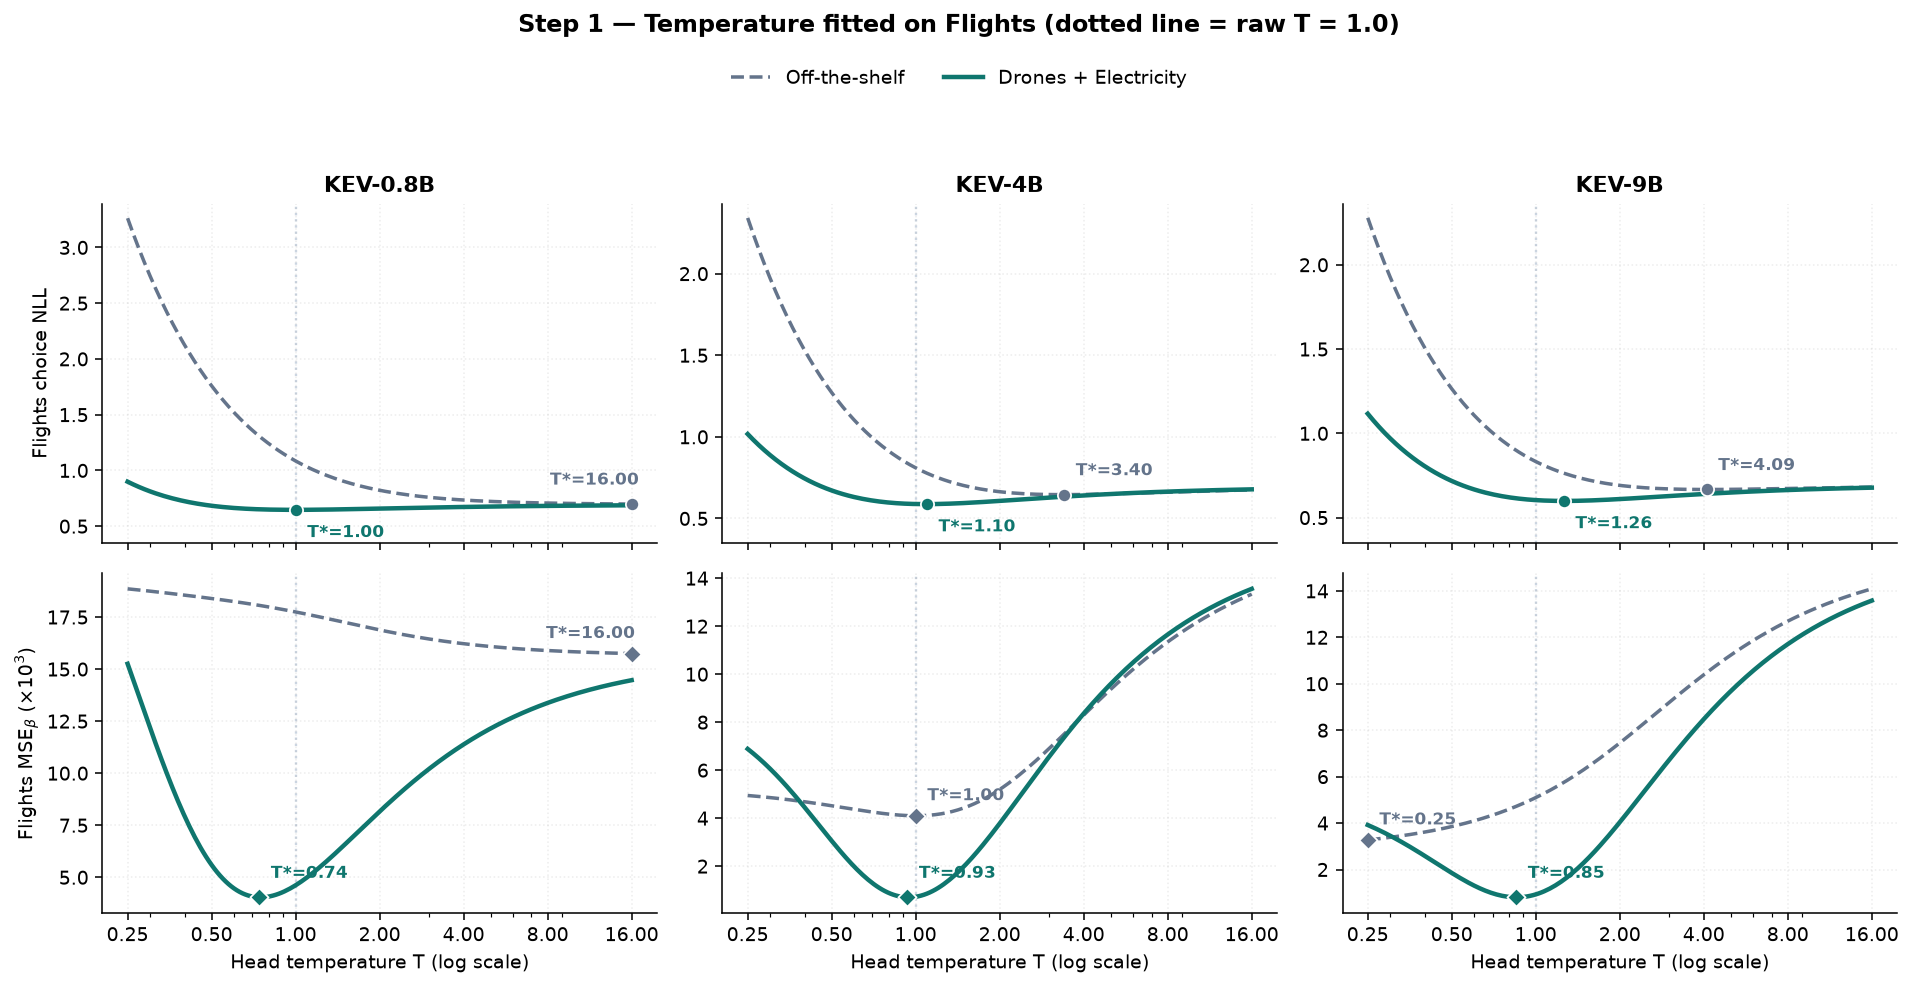

In [12]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(13.8, 6.8), sharex=True)

for col, model_slug in enumerate(MODELS):
    ax_nll = axes[0, col]
    ax_mse = axes[1, col]

    for ax in (ax_nll, ax_mse):
        ax.axvline(1.0, color="#CBD5E1", ls=":", lw=1.2, zorder=1)
        ax.set_xscale("log")
        ax.grid(alpha=0.22, ls=":")

    for regime_slug in REGIMES:
        color, ls, lw = REGIME_STYLES[regime_slug]
        c = flights_curves[(model_slug, regime_slug)]
        grid = c["grid_ext"]
        lbl = REGIME_LABELS[regime_slug]

        ax_nll.plot(grid, c["nll_ext"], color=color, ls=ls, lw=lw, label=lbl if col == 0 else None)
        ax_mse.plot(grid, c["mse_ext"] * 1e3, color=color, ls=ls, lw=lw)

        # Mark and annotate ONLY each panel's own optimum
        i_nll = int(np.argmin(c["nll_ext"]))
        t_nll, y_nll = float(grid[i_nll]), float(c["nll_ext"][i_nll])
        ax_nll.scatter([t_nll], [y_nll], color=color, s=46, zorder=5, edgecolor="white", lw=0.9)
        dx_nll = -42 if t_nll > 8.0 else 6
        dy_nll = 10 if regime_slug == "row1_base_untrained" else -14
        ax_nll.annotate(
            f"T*={t_nll:.2f}",
            (t_nll, y_nll),
            xytext=(dx_nll, dy_nll),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color=color,
        )

        i_mse = int(np.argmin(c["mse_ext"]))
        t_mse, y_mse = float(grid[i_mse]), float(c["mse_ext"][i_mse] * 1e3)
        ax_mse.scatter([t_mse], [y_mse], color=color, marker="D", s=44, zorder=5, edgecolor="white", lw=0.9)
        dx_mse = -44 if t_mse > 8.0 else 6
        dy_mse = 8 if regime_slug == "row1_base_untrained" else 10
        ax_mse.annotate(
            f"T*={t_mse:.2f}",
            (t_mse, y_mse),
            xytext=(dx_mse, dy_mse),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color=color,
        )

    ax_nll.set_title(MODEL_LABELS[model_slug], fontweight="bold", fontsize=11.5)
    ax_mse.set_xticks([0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0])
    ax_mse.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax_mse.xaxis.set_minor_formatter(plt.NullFormatter())
    ax_nll.set_ylim(bottom=0.35)
    ax_mse.set_xlabel("Head temperature T (log scale)")
    if col == 0:
        ax_nll.set_ylabel("Flights choice NLL")
        ax_mse.set_ylabel(r"Flights $\mathrm{MSE}_\beta$ ($\times 10^3$)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=len(REGIMES), frameon=False, fontsize=10)
fig.suptitle("Step 1 — Temperature fitted on Flights (dotted line = raw T = 1.0)", y=1.03, fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(POST_HOC_DIR / "fig_flights_temperature_curves.png", bbox_inches="tight")
plt.show()

## 4. Out-of-sample evaluation across all four held-out test datasets

Using only the single scalar temperature fitted on **Flights** (zero target-dataset human data), we evaluate every model and regime on **Consumer rights**, **AI & offshoring**, **Food labels**, and **Vaccines**.

In [13]:
# Build temperature settings per (model, regime) strictly from Flights fits (plus T=1.0 and KEV shipped T)
TEMP_METHODS = [
    "Raw (T = 1.0)",
    "KEV shipped T",
    "Flights NLL T* (KEV <=4)",
    "Flights NLL T* (ext)",
    "Flights MSE_beta T* (ext)",
]

eval_rows = []
for model_slug in MODELS:
    for regime_slug in REGIMES:
        c = flights_curves[(model_slug, regime_slug)]
        method_temps = {
            "Raw (T = 1.0)": 1.0,
            "KEV shipped T": c["shipped_t"],
            "Flights NLL T* (KEV <=4)": c["t_nll_kev"],
            "Flights NLL T* (ext)": c["t_nll_ext"],
            "Flights MSE_beta T* (ext)": c["t_beta_ext"],
        }
        for ds in ALL_DATASETS:
            bundle = cached_logits[(model_slug, regime_slug, ds)]
            ops = dataset_ops[ds]
            for method_name, temp_val in method_temps.items():
                res = eval_at_temperature(bundle, ops, temp_val)
                eval_rows.append(
                    {
                        "model_slug": model_slug,
                        "regime_slug": regime_slug,
                        "dataset": ds,
                        "role": "Validation" if ds == VALIDATION_DATASET else "Test",
                        "Model": MODEL_LABELS[model_slug],
                        "Regime": REGIME_LABELS[regime_slug],
                        "Dataset": DATASET_LABELS[ds],
                        "Method": method_name,
                        "T": float(temp_val),
                        "nll": res["nll"],
                        "beta_mse_x1e3": res["beta_mse"] * 1e3,
                        "scale_mse_x1e3": res["scale_mse"] * 1e3,
                        "shape_mse_x1e3": res["shape_mse"] * 1e3,
                        "pct_scale": res["pct_scale"],
                        "scale_ratio": res["scale_ratio"],
                        "cosine_sim": res["cosine_sim"],
                        "spearman_rho": res["spearman_rho"],
                    }
                )

eval_df = pd.DataFrame(eval_rows)
test_df = eval_df[eval_df["role"] == "Test"].copy()

# Headline pivot: Raw MSE_beta (x1e3) per test dataset + 4-dataset mean
mse_pivot = test_df.pivot(index=["Model", "Regime", "Method", "T"], columns="Dataset", values="beta_mse_x1e3")
mse_pivot = mse_pivot[[DATASET_LABELS[ds] for ds in TEST_DATASETS]]
mse_pivot["Test mean"] = mse_pivot.mean(axis=1)
shape_mean = test_df.groupby(["Model", "Regime", "Method", "T"])["shape_mse_x1e3"].mean()
nll_mean = test_df.groupby(["Model", "Regime", "Method", "T"])["nll"].mean()
mse_pivot["Shape MSE mean"] = shape_mean
mse_pivot["Test NLL mean"] = nll_mean

model_order = [MODEL_LABELS[m] for m in MODELS]
regime_order = [REGIME_LABELS[r] for r in REGIMES]
mse_pivot = mse_pivot.reset_index()
mse_pivot["Model"] = pd.Categorical(mse_pivot["Model"], categories=model_order, ordered=True)
mse_pivot["Regime"] = pd.Categorical(mse_pivot["Regime"], categories=regime_order, ordered=True)
mse_pivot["Method"] = pd.Categorical(mse_pivot["Method"], categories=TEMP_METHODS, ordered=True)
mse_pivot = mse_pivot.sort_values(["Model", "Regime", "Method"]).set_index(["Model", "Regime", "Method"])
mse_pivot["T"] = mse_pivot["T"].round(3)
print("Held-out test datasets: raw MSE_beta (x1e3), 4-dataset mean, Shape MSE mean, and choice NLL mean")
display(mse_pivot.round(3))

Held-out test datasets: raw MSE_beta (x1e3), 4-dataset mean, Shape MSE mean, and choice NLL mean


Dataset                                                       T  Consumer rights  AI & offshoring  Food labels  Vaccines  Test mean  Shape MSE mean  Test NLL mean
Model    Regime               Method                                                                                                                              
KEV-0.8B Off-the-shelf        Raw (T = 1.0)               1.000            8.339           33.918        5.463    12.073     14.948          13.054          1.486
                              KEV shipped T               2.351            8.262           32.464        7.545     5.522     13.448          12.393          1.151
                              Flights NLL T* (KEV <=4)    4.000            8.303           33.103       10.589     5.018     14.253          12.272          1.112
                              Flights NLL T* (ext)       16.000            8.478           36.743       16.336     5.806     16.840          12.190          1.114
                              Flights MSE_beta T* (ext)  16.000            8.478           36.743       16.336     5.806     16.840          12.190          1.114
         Drones + Electricity Raw (T = 1.0)               1.000            6.037           26.614        2.303     2.564      9.379           8.684          1.050
                              KEV shipped T               2.351            7.314           30.119        7.224     4.046     12.175           8.607          1.071
                              Flights NLL T* (KEV <=4)    1.000            6.037           26.614        2.303     2.564      9.379           8.684          1.050
                              Flights NLL T* (ext)        1.000            6.037           26.614        2.303     2.564      9.379           8.684          1.050
                              Flights MSE_beta T* (ext)   0.741            5.485           26.385        2.541     2.582      9.248           8.783          1.061
KEV-4B   Off-the-shelf        Raw (T = 1.0)               1.000            4.888           99.176       21.097     9.084     33.561           8.845          1.460
                              KEV shipped T               2.406            6.436           66.898        9.552     2.290     21.294           8.669          1.115
                              Flights NLL T* (KEV <=4)    3.403            6.967           46.394       10.467     1.526     16.339           8.658          1.085
                              Flights NLL T* (ext)        3.403            6.967           46.394       10.467     1.526     16.339           8.658          1.085
                              Flights MSE_beta T* (ext)   1.000            4.888           99.176       21.097     9.084     33.561           8.845          1.460
         Drones + Electricity Raw (T = 1.0)               1.000            2.253           63.931        2.278     1.115     17.394           4.894          1.041
                              KEV shipped T               2.406            5.134           20.350        7.422     1.554      8.615           4.910          1.045
                              Flights NLL T* (KEV <=4)    1.097            2.555           58.084        2.288     0.807     15.933           4.893          1.035
                              Flights NLL T* (ext)        1.097            2.555           58.084        2.288     0.807     15.933           4.893          1.035
                              Flights MSE_beta T* (ext)   0.933            2.039           68.204        2.419     1.426     18.522           4.895          1.048
KEV-9B   Off-the-shelf        Raw (T = 1.0)               1.000            1.763           82.647       22.732    14.298     30.360           6.311          1.475
                              KEV shipped T               2.194            3.241           58.140        4.825     3.504     17.428           5.632          1.112
                              Flights NLL T* (KEV <=4)    4.000            4.958        

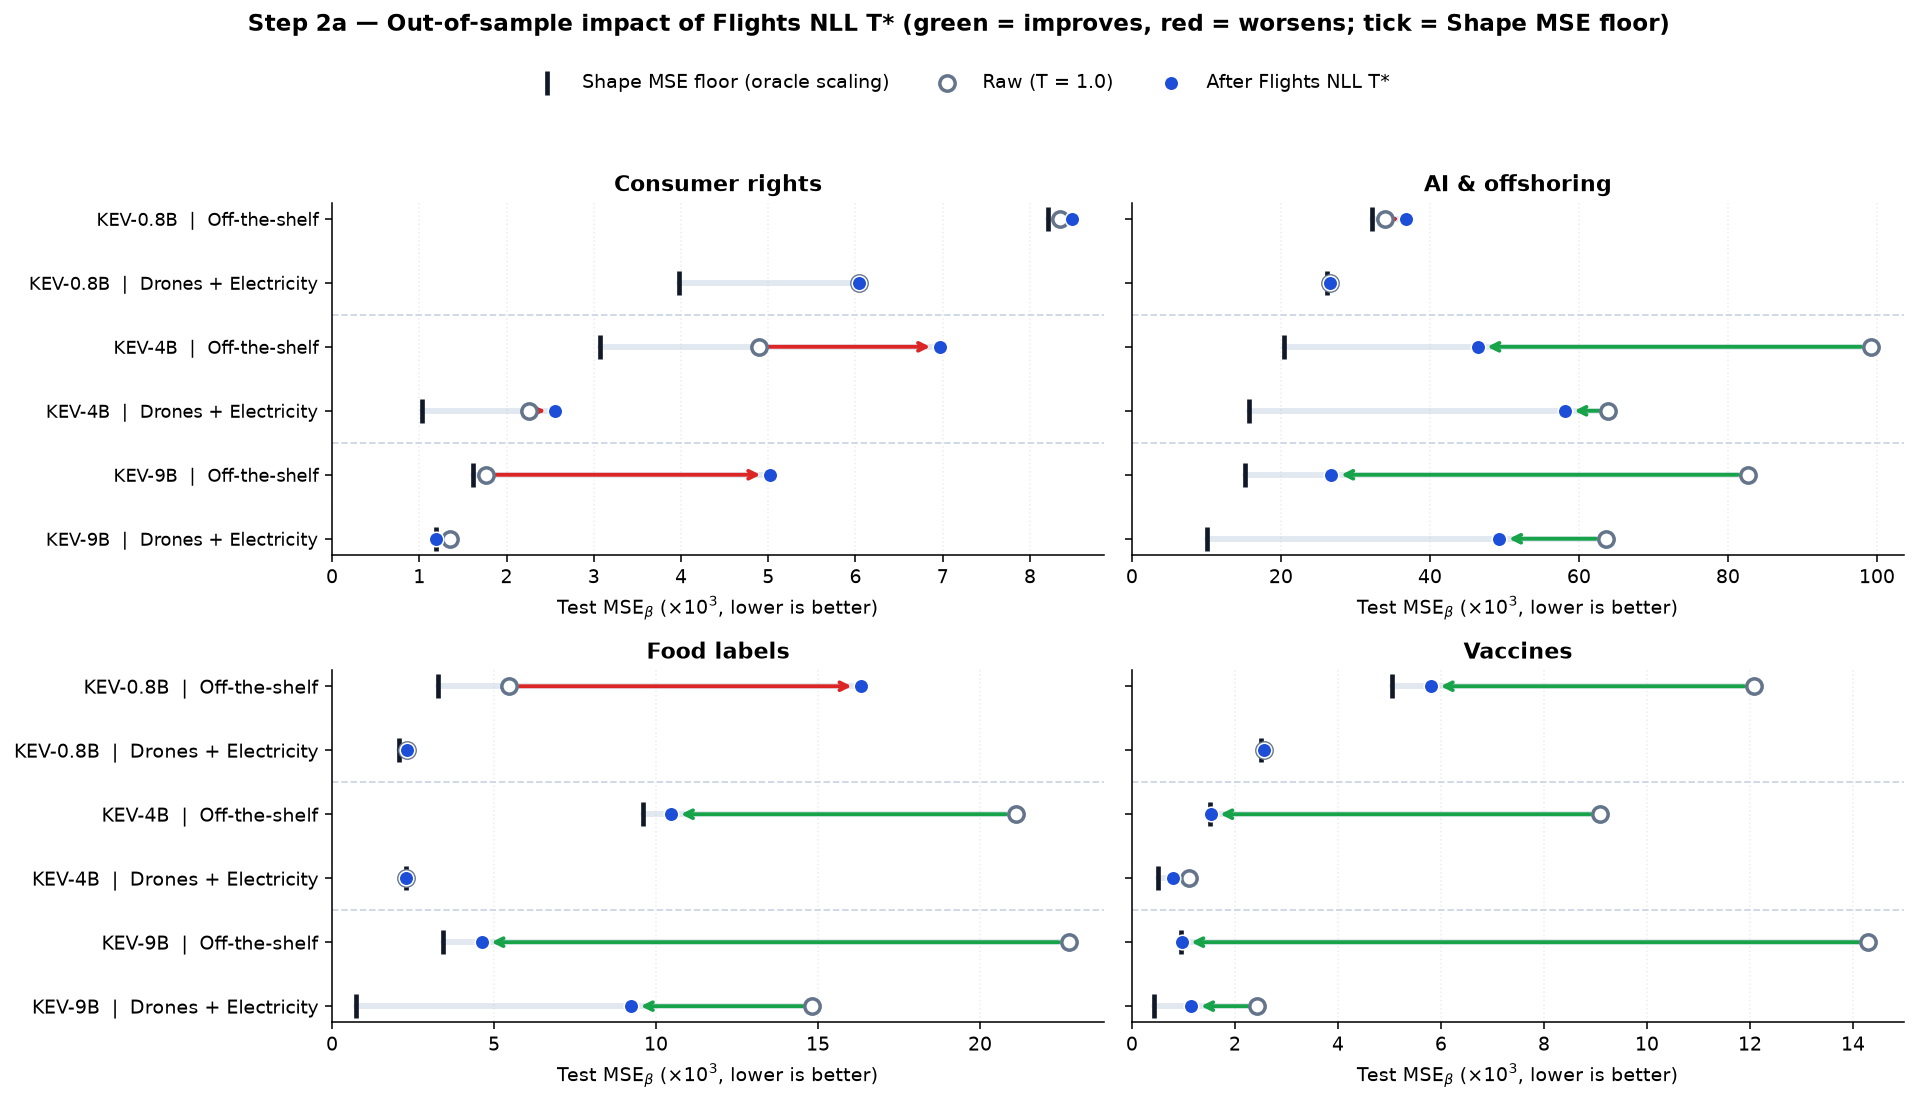

In [17]:
def plot_oos_temperature_impact(
    method_key: str,
    method_label: str,
    dot_color: str,
    title: str,
    save_name: str,
) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(13.8, 7.6), sharey=True)
    axes_flat = axes.ravel()

    combos = [(m, r) for m in MODELS for r in REGIMES]
    n_reg = len(REGIMES)
    y_pos = np.arange(len(combos), dtype=float)
    y_labels = [f"{MODEL_LABELS[m]}  |  {REGIME_LABELS[r]}" for m, r in combos]

    for idx_ds, (ax, ds) in enumerate(zip(axes_flat, TEST_DATASETS, strict=True)):
        sub = test_df[test_df["dataset"] == ds]
        raw_vals, cal_vals, shape_vals = [], [], []
        for m, r in combos:
            row_raw = sub[(sub["model_slug"] == m) & (sub["regime_slug"] == r) & (sub["Method"] == "Raw (T = 1.0)")].iloc[0]
            row_cal = sub[(sub["model_slug"] == m) & (sub["regime_slug"] == r) & (sub["Method"] == method_key)].iloc[0]
            raw_vals.append(float(row_raw["beta_mse_x1e3"]))
            cal_vals.append(float(row_cal["beta_mse_x1e3"]))
            shape_vals.append(float(row_cal["shape_mse_x1e3"]))

        x_span = max(max(raw_vals), max(cal_vals), 1e-6)
        for i, (v_raw, v_cal, v_sh) in enumerate(zip(raw_vals, cal_vals, shape_vals, strict=True)):
            ax.plot([v_sh, max(v_raw, v_cal)], [i, i], color="#E2E8F0", lw=3.0, zorder=1, solid_capstyle="round")
            if abs(v_cal - v_raw) > 0.025 * x_span:
                arrow_color = "#16A34A" if v_cal < v_raw else "#DC2626"
                ax.annotate(
                    "",
                    xy=(v_cal, i),
                    xytext=(v_raw, i),
                    arrowprops=dict(arrowstyle="->", color=arrow_color, lw=2.0, shrinkA=5, shrinkB=5),
                    zorder=3,
                )

        ax.scatter(
            shape_vals, y_pos, marker="|", s=140, lw=2.4, color=COLOR_SHAPE, zorder=4,
            label="Shape MSE floor (oracle scaling)" if idx_ds == 0 else None,
        )
        ax.scatter(
            raw_vals, y_pos, s=62, facecolor="white", edgecolor="#64748B", lw=1.8, zorder=5,
            label="Raw (T = 1.0)" if idx_ds == 0 else None,
        )
        ax.scatter(
            cal_vals, y_pos, s=56, color=dot_color, edgecolor="white", lw=0.8, zorder=6,
            label=method_label if idx_ds == 0 else None,
        )

        for sep in [mi * n_reg - 0.5 for mi in range(1, len(MODELS))]:
            ax.axhline(sep, color="#CBD5E1", lw=0.9, ls="--")

        ax.set_title(DATASET_LABELS[ds], fontweight="bold", fontsize=11.5)
        ax.set_xlabel(r"Test $\mathrm{MSE}_\beta$ ($\times 10^3$, lower is better)")
        ax.set_xlim(left=0)
        ax.grid(axis="x", alpha=0.22, ls=":")

    axes_flat[0].set_yticks(y_pos)
    axes_flat[0].set_yticklabels(y_labels, fontsize=9.2)
    axes_flat[0].invert_yaxis()

    handles, labels = axes_flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=3, frameon=False, fontsize=10)
    fig.suptitle(title, y=1.03, fontsize=12.0, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(POST_HOC_DIR / save_name, bbox_inches="tight")
    plt.show()


plot_oos_temperature_impact(
    method_key="Flights NLL T* (ext)",
    method_label="After Flights NLL T*",
    dot_color=COLOR_NLL,
    title="Step 2a — Out-of-sample impact of Flights NLL T* (green = improves, red = worsens; tick = Shape MSE floor)",
    save_name="fig_test_temperature_impact_nll.png",
)

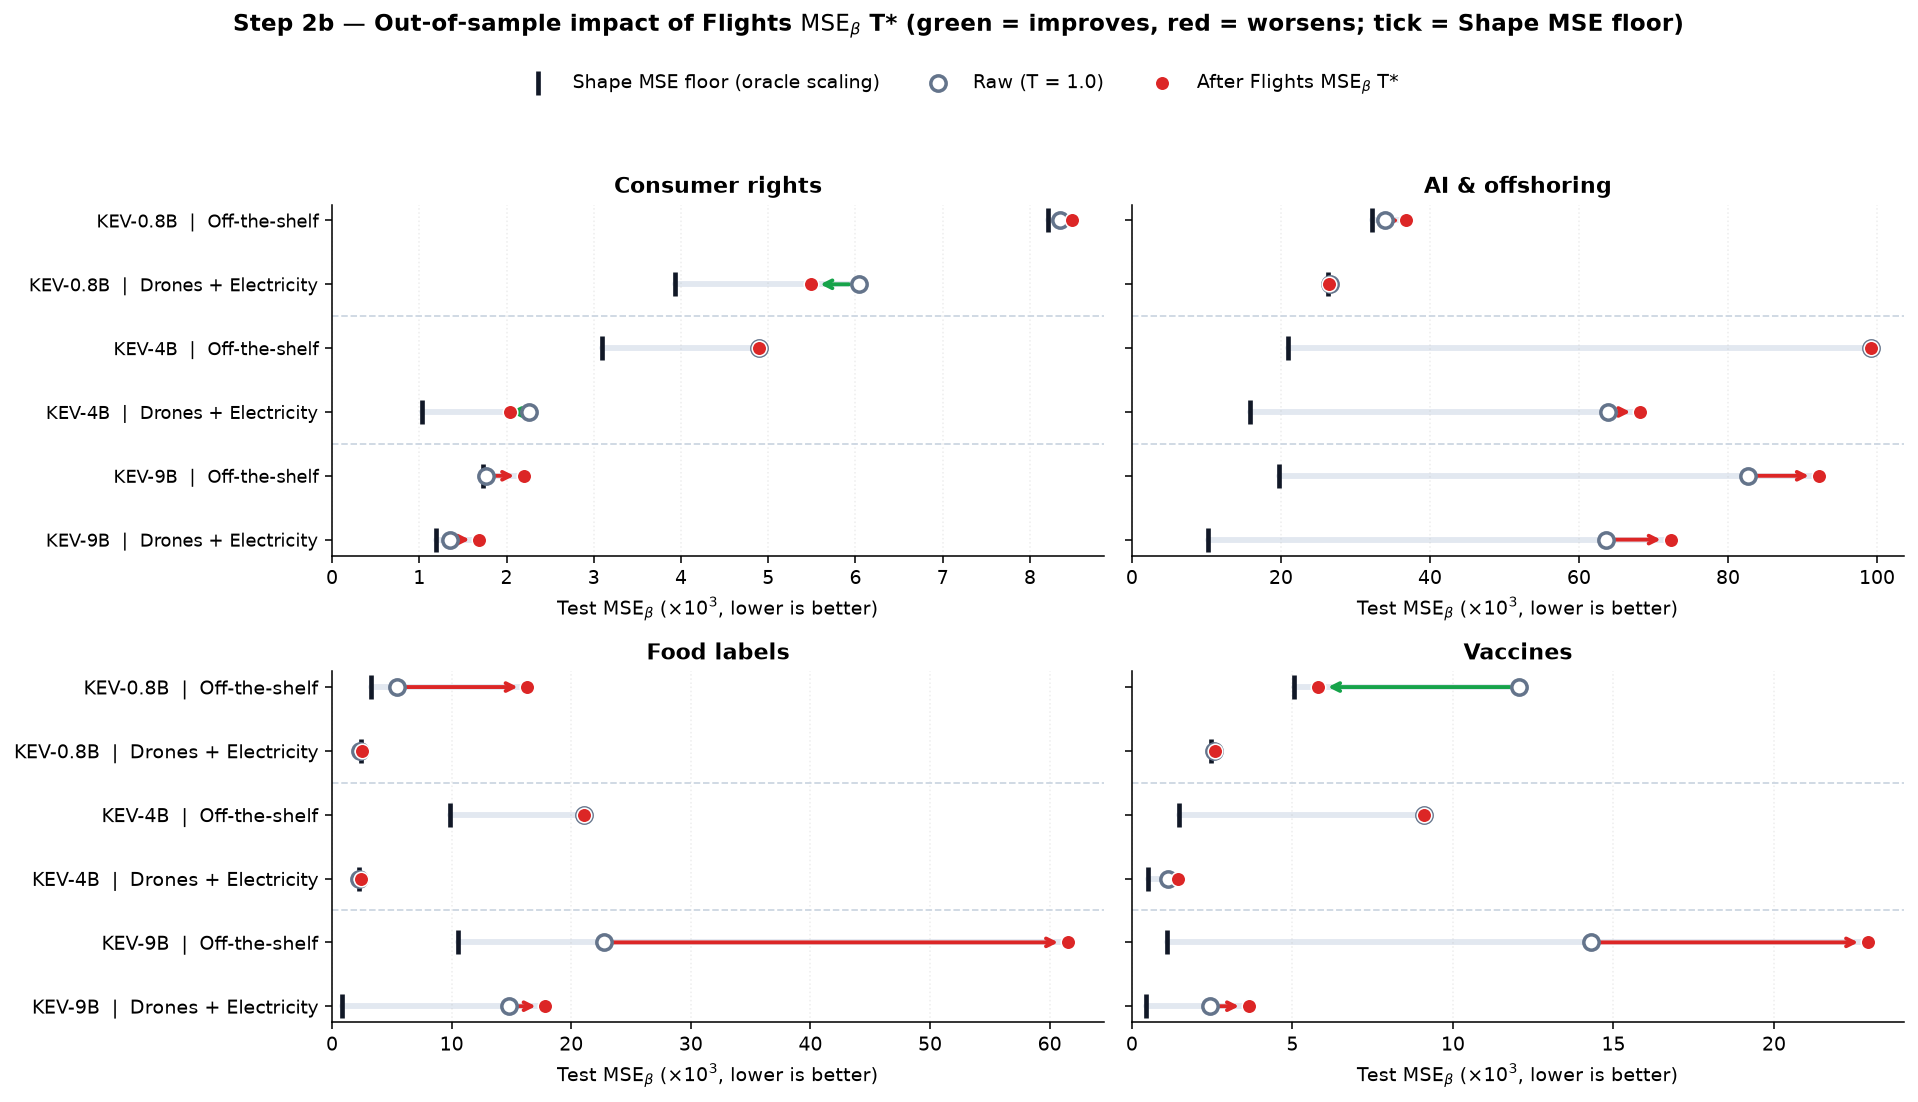

In [18]:
plot_oos_temperature_impact(
    method_key="Flights MSE_beta T* (ext)",
    method_label=r"After Flights $\mathrm{MSE}_\beta$ T*",
    dot_color=COLOR_BETA,
    title=r"Step 2b — Out-of-sample impact of Flights $\mathrm{MSE}_\beta$ T* (green = improves, red = worsens; tick = Shape MSE floor)",
    save_name="fig_test_temperature_impact_beta_mse.png",
)

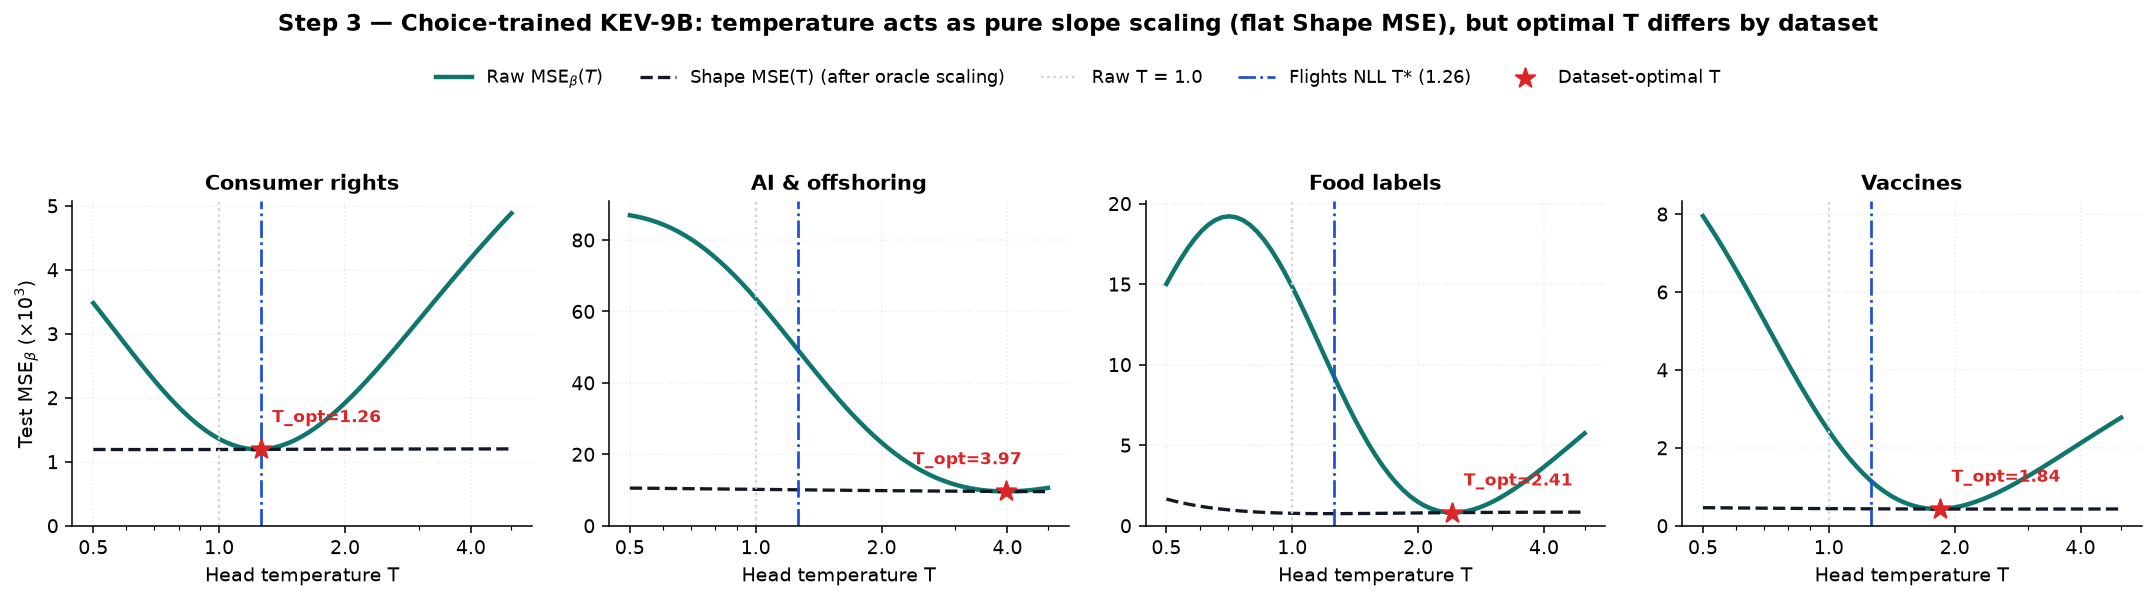

In [15]:
# Sweep temperature across held-out test datasets for choice-trained KEV-9B (Drones + Electricity)
sweep_grid = np.exp(np.linspace(np.log(0.5), np.log(5.0), 61))
target_model = "kev-9b"
target_regime = "row5_full_berke_wu_ce_oracle"
t_flights_nll = flights_curves[(target_model, target_regime)]["t_nll_ext"]

fig, axes = plt.subplots(1, len(TEST_DATASETS), figsize=(15.5, 4.0), sharex=True)

for idx_ds, (ax, ds) in enumerate(zip(axes, TEST_DATASETS, strict=True)):
    bundle = cached_logits[(target_model, target_regime, ds)]
    ops = dataset_ops[ds]
    raw_curve, shape_curve = [], []
    for t in sweep_grid:
        res = eval_at_temperature(bundle, ops, float(t))
        raw_curve.append(res["beta_mse"] * 1e3)
        shape_curve.append(res["shape_mse"] * 1e3)
    raw_curve = np.asarray(raw_curve)
    shape_curve = np.asarray(shape_curve)

    i_opt = int(np.argmin(raw_curve))
    t_opt, y_opt = float(sweep_grid[i_opt]), float(raw_curve[i_opt])

    ax.plot(sweep_grid, raw_curve, color=COLOR_FULL, lw=2.3, label=r"Raw $\mathrm{MSE}_\beta(T)$" if idx_ds == 0 else None)
    ax.plot(sweep_grid, shape_curve, color=COLOR_SHAPE, ls="--", lw=1.7, label="Shape MSE(T) (after oracle scaling)" if idx_ds == 0 else None)
    ax.axvline(1.0, color="#CBD5E1", ls=":", lw=1.2, label="Raw T = 1.0" if idx_ds == 0 else None)
    ax.axvline(t_flights_nll, color=COLOR_NLL, ls="-.", lw=1.4, label=f"Flights NLL T* ({t_flights_nll:.2f})" if idx_ds == 0 else None)
    ax.scatter([t_opt], [y_opt], color=COLOR_BETA, marker="*", s=110, zorder=6, label="Dataset-optimal T" if idx_ds == 0 else None)

    ax.annotate(
        f"T_opt={t_opt:.2f}",
        (t_opt, y_opt),
        xytext=(-48 if t_opt > 3.2 else 6, 14),
        textcoords="offset points",
        fontsize=8.8,
        fontweight="bold",
        color=COLOR_BETA,
    )
    ax.set_title(DATASET_LABELS[ds], fontweight="bold", fontsize=11.0)
    ax.set_xscale("log")
    ax.set_xticks([0.5, 1.0, 2.0, 4.0])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Head temperature T")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.22, ls=":")
    if idx_ds == 0:
        ax.set_ylabel(r"Test $\mathrm{MSE}_\beta$ ($\times 10^3$)")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=5, frameon=False, fontsize=9.3)
fig.suptitle(
    "Step 3 — Choice-trained KEV-9B: temperature acts as pure slope scaling (flat Shape MSE), but optimal T differs by dataset",
    y=1.06,
    fontsize=11.8,
    fontweight="bold",
)
plt.tight_layout(rect=[0, 0, 1, 0.89])
fig.savefig(POST_HOC_DIR / "fig_temperature_vs_shape_floor.png", bbox_inches="tight")
plt.show()

## 5. Paradox check: Off-the-shelf `KEV-0.8B` vs. choice-trained `KEV-9B` (`Drones + Electricity`)

Checks whether fitting a single scalar head temperature on **Flights** resolves the raw-$\mathrm{MSE}_\beta$ paradox across held-out test datasets without using any target-dataset human data.

In [16]:
paradox_mask = (
    ((test_df["model_slug"] == "kev-0.8b") & (test_df["regime_slug"] == "row1_base_untrained"))
    | ((test_df["model_slug"] == "kev-9b") & (test_df["regime_slug"] == "row5_full_berke_wu_ce_oracle"))
) & (test_df["Method"].isin(["Raw (T = 1.0)", "Flights NLL T* (ext)", "Flights MSE_beta T* (ext)"]))

paradox_df = (
    test_df[paradox_mask]
    .assign(
        Config=lambda d: d["Model"] + " (" + d["Regime"] + ")",
        Method=lambda d: pd.Categorical(d["Method"], categories=["Raw (T = 1.0)", "Flights NLL T* (ext)", "Flights MSE_beta T* (ext)"], ordered=True),
        Dataset=lambda d: pd.Categorical(d["Dataset"], categories=[DATASET_LABELS[ds] for ds in TEST_DATASETS], ordered=True),
    )
    .sort_values(["Dataset", "Method", "Config"])
    [["Dataset", "Method", "Config", "T", "beta_mse_x1e3", "shape_mse_x1e3", "scale_ratio", "cosine_sim", "nll"]]
    .set_index(["Dataset", "Method", "Config"])
)
display(paradox_df.round(3))

# Save summary tables into logits_cache/ for easy downstream inspection
flights_fit_df.to_csv(LOGITS_DIR / "flights_temperature_fits.csv", index=False)
eval_df.to_csv(LOGITS_DIR / "test_temperature_evaluation.csv", index=False)
print(f"Saved summary CSVs to {LOGITS_DIR.relative_to(POST_HOC_DIR)}/")

T  beta_mse_x1e3  shape_mse_x1e3  scale_ratio  cosine_sim    nll
Dataset         Method                    Config                                                                                              
Consumer rights Raw (T = 1.0)             KEV-0.8B (Off-the-shelf)        1.000          8.339           8.339        0.970       0.165  1.418
                                          KEV-9B (Drones + Electricity)   1.000          1.357           1.191        1.150       0.928  0.666
                Flights NLL T* (ext)      KEV-0.8B (Off-the-shelf)       16.000          8.478           8.211        0.140       0.205  0.698
                                          KEV-9B (Drones + Electricity)   1.260          1.194           1.193        0.988       0.928  0.642
                Flights MSE_beta T* (ext) KEV-0.8B (Off-the-shelf)       16.000          8.478           8.211        0.140       0.205  0.698
                                          KEV-9B (Drones + Electricity)   0.851          1.688           1.191        1.260       0.928  0.694
AI & offshoring Raw (T = 1.0)             KEV-0.8B (Off-the-shelf)        1.000         33.918          33.574        0.755       0.382  2.283
                                          KEV-9B (Drones + Electricity)   1.000         63.606          10.186        2.355       0.861  1.658
                Flights NLL T* (ext)      KEV-0.8B (Off-the-shelf)       16.000         36.743          32.225        0.201       0.424  1.582
                                          KEV-9B (Drones + Electricity)   1.260         49.310          10.061        2.159       0.863  1.590
                Flights MSE_beta T* (ext) KEV-0.8B (Off-the-shelf)       16.000         36.743          32.225        0.201       0.424  1.582
                                          KEV-9B (Drones + Electricity)   0.851         72.283          10.272        2.462       0.859  1.731
Food labels     Raw (T = 1.0)             KEV-0.8B (Off-the-shelf)        1.000          5.463           5.408        0.936       0.846  1.059
                                          KEV-9B (Drones + Electricity)   1.000         14.822           0.770        1.878       0.980  0.808
                Flights NLL T* (ext)      KEV-0.8B (Off-the-shelf)       16.000         16.336           3.272        0.088       0.910  1.081
                                          KEV-9B (Drones + Electricity)   1.260          9.228           0.750        1.682       0.980  0.805
                Flights MSE_beta T* (ext) KEV-0.8B (Off-the-shelf)       16.000         16.336           3.272        0.088       0.910  1.081
                                          KEV-9B (Drones + Electricity)   0.851         17.842           0.831        1.968       0.978  0.826
Vaccines        Raw (T = 1.0)             KEV-0.8B (Off-the-shelf)        1.000         12.073           4.894        3.167       0.488  1.185
                                          KEV-9B (Drones + Electricity)   1.000          2.432           0.439        1.577       0.965  1.100
                Flights NLL T* (ext)      KEV-0.8B (Off-the-shelf)       16.000          5.806           5.053        0.259       0.462  1.096
                                          KEV-9B (Drones + Electricity)   1.260          1.154           0.433        1.347       0.966  1.051
                Flights MSE_beta T* (ext) KEV-0.8B (Off-the-shelf)       16.000          5.806           5.053        0.259       0.462  1.096
                                          KEV-9B (Drones + Electricity)   0.851          3.640           0.444        1.731       0.965  1.154

Saved summary CSVs to logits_cache/
